# IFC to graph dataset (data pipeline)

**Goal.** Turn every IFCNetCore element (one `.ifc` file each) into a small **graph** that a graph neural network can read, and save it outside git together with a train/val/test split file. A graph autoencoder can then be trained on it without redoing any preprocessing.

**Why graphs and not images.** The previous notebook (`autoencoder.ipynb`) used PNG renders and convolutional layers. Here we work directly on the 3D geometry stored in the IFC file, as the course asked, and we avoid convolutions.

**Rule against data leakage.** The model input is **geometry only** (point coordinates and their neighbour links). The IFC class, the element name and its properties are never model inputs. The class is kept aside only to stratify the split and to evaluate the results.

**Dataset.** IFCNetCore (Emunds et al. 2021, arXiv 2106.09712). No licence is stated, so the files stay in `data/` (git-ignored) and are never uploaded.

## 0. Setup

We import the libraries, fix the random **seed** (so every run gives the same result) and define the folders with **relative paths** (so the notebook works on any teammate's computer, as long as the repo layout is the same). This notebook lives in `01_autoencoder/notebook/`, so the data folder is two levels up.

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ifcopenshell

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA = Path("../../data")              # git-ignored data folder
IFC_ROOT = DATA / "IFCNetCoreIFC"      # unzipped IFCNetCoreIFC.zip
FIG = Path("../figures")               # figures are committed
FIG.mkdir(exist_ok=True)

assert IFC_ROOT.exists(), f"IFC folder not found: {IFC_ROOT.resolve()}"
print("IFC root:", IFC_ROOT)
print("ifcopenshell", ifcopenshell.version)

IFC root: ../../data/IFCNetCoreIFC
ifcopenshell 0.9.0.post1


## 1. Explore the data

### 1.1 Build a file index

The unzipped dataset is organised as `IFCNetCoreIFC/<IfcClass>/<train|test>/<id>.ifc`. The file name is only a random identifier; the **class comes from the folder name**, and the dataset authors already provide an official train/test division in the sub-folders.

We list every file once and store it in a table (`index`). Each row is one object. The `path` column is relative to `data/`, so it also works on another computer. Every later step (split, conversion, saving) starts from this table, so we read the folders only once.

In [2]:
files = sorted(IFC_ROOT.glob("*/*/*.ifc"))

index = pd.DataFrame({
    "object_id": [f.stem for f in files],                  # random id from the file name
    "ifc_class": [f.parts[-3] for f in files],             # label = folder name
    "official_split": [f.parts[-2] for f in files],        # 'train' or 'test' folder
    "path": [f.relative_to(DATA).as_posix() for f in files],
})

print(len(index), "IFC files,", index["ifc_class"].nunique(), "classes")
print("every object_id is unique:", index["object_id"].is_unique)
index.head()

7930 IFC files, 20 classes
every object_id is unique: True


,object_id,ifc_class,official_split,path
0,0040c7bf0e474141bb19bdf8ed59e080,IfcAirTerminal,test,IFCNetCoreIFC/IfcAirTerminal/test/0040c7bf0e47...
1,04327ff13a5547a3b2ab3fa7377d5a26,IfcAirTerminal,test,IFCNetCoreIFC/IfcAirTerminal/test/04327ff13a55...
2,074813d22a894bd299966b7fb2163749,IfcAirTerminal,test,IFCNetCoreIFC/IfcAirTerminal/test/074813d22a89...
3,09436112504444c08a798db5b213f1ed,IfcAirTerminal,test,IFCNetCoreIFC/IfcAirTerminal/test/094361125044...
4,096f0d41983e4ac5b3b3f54485a9dc8c,IfcAirTerminal,test,IFCNetCoreIFC/IfcAirTerminal/test/096f0d41983e...


### 1.2 How many objects per class

We count objects per class and per official folder. This matters for two decisions: (1) the split must keep every class in train, val and test, and (2) the classes we may later call "anomalies" need enough objects to give a meaningful test.

In [3]:
counts = pd.crosstab(index["ifc_class"], index["official_split"])
counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("total", ascending=False)
print(counts.to_string())
print("\nall classes:", counts.sum().to_dict())

official_split          test  train  total
ifc_class                                 
IfcDuctFitting           195    455    650
IfcPipeSegment           195    454    649
IfcPipeFitting           194    454    648
IfcWall                  161    376    537
IfcDuctSegment           159    372    531
IfcCableCarrierSegment   159    370    529
IfcPlate                 157    366    523
IfcCableCarrierFitting   155    361    516
IfcSlab                  152    355    507
IfcAirTerminal           142    333    475
IfcSanitaryTerminal      136    316    452
IfcRailing               127    295    422
IfcValve                 104    242    346
IfcDoor                   93    216    309
IfcBeam                   84    198    282
IfcFurniture              67    157    224
IfcSpaceHeater            38     89    127
IfcLamp                   27     65     92
IfcOutlet                 18     41     59
IfcStair                  16     36     52

all classes: {'test': 2379, 'train': 5551, 'total': 7

The same totals as a chart. Only the small classes (fewer than 100 objects) get a number, because those are the ones that limit what we can test.

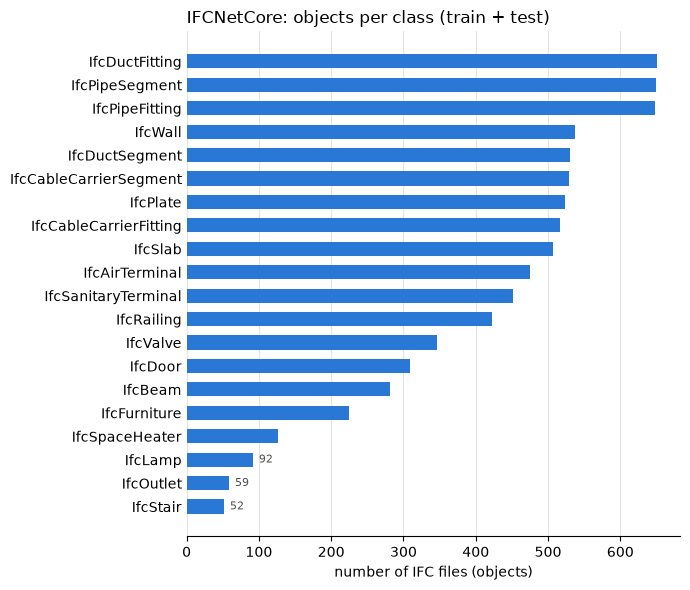

In [4]:
tot = counts["total"].sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(tot.index, tot.values, color="#2a78d6", height=0.6)
for y, v in enumerate(tot.values):
    if v < 100:
        ax.text(v + 8, y, str(v), va="center", fontsize=8, color="#52514e")
ax.set_title("IFCNetCore: objects per class (train + test)", loc="left")
ax.set_xlabel("number of IFC files (objects)")
ax.grid(axis="x", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIG / "ifc_01_class_counts.png", dpi=150)
plt.show()

### 1.3 What is inside one IFC file

Before trusting the folder name as the label, we open every file with IfcOpenShell and check three things:

- **schema**: the IFC version (IFC2X3 or IFC4). The geometry reader must handle both.
- **number of elements with geometry**: we expect exactly one element per file. If a file had several, we would need to choose which one to convert.
- **inner entity**: the IFC class written inside the file. We compare it with the folder name.

This is only a check. The inner entity is **not** stored in the split file and is **never** a model input. Opening all files takes about half a minute.

In [5]:
def inspect_ifc(path):
    """Return the schema, the number of elements with geometry, and their IFC entity name."""
    model = ifcopenshell.open(str(path))
    products = [p for p in model.by_type("IfcProduct") if p.Representation is not None]
    return {
        "schema": model.schema,
        "n_geometric_elements": len(products),
        "inner_entity": products[0].is_a() if len(products) == 1 else None,
    }

audit = pd.DataFrame([inspect_ifc(DATA / p) for p in index["path"]])
audit.insert(0, "ifc_class", index["ifc_class"].values)
audit["same_as_folder"] = audit["inner_entity"] == audit["ifc_class"]

print("schemas:", audit["schema"].value_counts().to_dict())
print("elements with geometry per file:", audit["n_geometric_elements"].value_counts().to_dict())
print(f"inner entity equals folder class: {audit['same_as_folder'].sum()} / {len(audit)}")

schemas: {'IFC2X3': 4247, 'IFC4': 3683}
elements with geometry per file: {1: 7930}
inner entity equals folder class: 4777 / 7930


Per class: how many files have an inner entity equal to the folder name, and which entities appear instead.

In [6]:
pd.set_option("display.max_colwidth", None)
per_class = audit.groupby("ifc_class").agg(
    files=("inner_entity", "size"),
    same_as_folder=("same_as_folder", "sum"),
    inner_entities=("inner_entity", lambda s: ", ".join(f"{k} ({v})" for k, v in s.value_counts().items())),
)
per_class

,files,same_as_folder,inner_entities
ifc_class,,,
IfcAirTerminal,475,414,"IfcAirTerminal (414), IfcFlowTerminal (56), IfcBuildingElementProxy (4), IfcDistributionElement (1)"
IfcBeam,282,263,"IfcBeam (263), IfcBuildingElementProxy (11), IfcBeamStandardCase (8)"
IfcCableCarrierFitting,516,424,"IfcCableCarrierFitting (424), IfcFlowFitting (92)"
IfcCableCarrierSegment,529,430,"IfcCableCarrierSegment (430), IfcFlowSegment (80), IfcBuildingElementProxy (19)"
IfcDoor,309,309,IfcDoor (309)
IfcDuctFitting,650,38,"IfcFlowFitting (612), IfcDuctFitting (38)"
IfcDuctSegment,531,175,"IfcFlowSegment (351), IfcDuctSegment (175), IfcBuildingElementProxy (5)"
IfcFurniture,224,154,"IfcFurniture (154), IfcFurnishingElement (52), IfcBuildingElementProxy (18)"
IfcLamp,92,0,IfcFlowTerminal (92)


### 1.4 Findings

- **7,930 objects in 20 classes**, one IFC file per object (5,551 in the official `train` folders, 2,379 in `test`). Every file name is unique, so the file name works as the object id.
- **Exactly one element with geometry per file**, so there is no choice to make about which element to convert.
- **Two schemas**: 4,247 files are IFC2X3 and 3,683 are IFC4. The geometry reader must work for both.
- **The class written inside the file is not reliable**: it matches the folder in only 4,777 of 7,930 files. Many elements were exported with generic entities (`IfcFlowSegment`, `IfcFlowFitting`, `IfcFlowTerminal`, `IfcBuildingElementProxy`). For `IfcLamp`, `IfcPipeSegment` and `IfcSanitaryTerminal` it never matches. **Decision: the label is the folder name**, as the dataset authors intended.
- This is also a reminder of why the class must not leak into the model: the geometry has to carry the information on its own.
- **Small classes**: `IfcStair` has only **52** objects (36 train, 16 test), `IfcOutlet` 59, `IfcSpaceHeater` 127 and `IfcLamp` 92. `IfcRailing` has 422. Any anomaly test built on `IfcStair` alone would rest on very few objects.

## 2. Train / validation / test split

We fix the split **before** converting any geometry, so that no later choice (number of points, neighbours, model size...) can be tuned by looking at the test objects.

- **test**: the official `test` folders of IFCNet (2,379 objects). Keeping the authors' test set makes our results comparable with the paper and with the team's point-cloud notebook.
- **val**: 15 % of the official `train` folders, chosen at random with the fixed seed. It is used to pick the best epoch and settings.
- **train**: the remaining 85 % of the official `train` folders.

The split is **by object**: each object (one IFC file) belongs to exactly one set. It is **stratified by class**, so each class keeps the same share in train and val, even the small ones like `IfcStair`. The class is used here only as a label to balance the split; it is not a model input.

All 20 classes are kept in the split. Which classes count as "anomalies" is decided later, during training, by leaving them out of the training data. This way the split does not depend on that decision.

In [7]:
from sklearn.model_selection import train_test_split

VAL_FRACTION = 0.15

official_train = index[index["official_split"] == "train"]
train_ids, val_ids = train_test_split(
    official_train["object_id"],
    test_size=VAL_FRACTION,
    stratify=official_train["ifc_class"],   # same class balance in train and val
    random_state=SEED,                      # same split on every run
)

split = index[["object_id", "ifc_class", "path"]].copy()
split["split"] = "test"
split.loc[split["object_id"].isin(train_ids), "split"] = "train"
split.loc[split["object_id"].isin(val_ids), "split"] = "val"
split = split[["object_id", "ifc_class", "split", "path"]]

print(split["split"].value_counts().reindex(["train", "val", "test"]).to_string())
split.head()

split
train    4718
val       833
test     2379


,object_id,ifc_class,split,path
0,0040c7bf0e474141bb19bdf8ed59e080,IfcAirTerminal,test,IFCNetCoreIFC/IfcAirTerminal/test/0040c7bf0e474141bb19bdf8ed59e080.ifc
1,04327ff13a5547a3b2ab3fa7377d5a26,IfcAirTerminal,test,IFCNetCoreIFC/IfcAirTerminal/test/04327ff13a5547a3b2ab3fa7377d5a26.ifc
2,074813d22a894bd299966b7fb2163749,IfcAirTerminal,test,IFCNetCoreIFC/IfcAirTerminal/test/074813d22a894bd299966b7fb2163749.ifc
3,09436112504444c08a798db5b213f1ed,IfcAirTerminal,test,IFCNetCoreIFC/IfcAirTerminal/test/09436112504444c08a798db5b213f1ed.ifc
4,096f0d41983e4ac5b3b3f54485a9dc8c,IfcAirTerminal,test,IFCNetCoreIFC/IfcAirTerminal/test/096f0d41983e4ac5b3b3f54485a9dc8c.ifc


### Check the split

Three automatic checks, so a mistake stops the notebook instead of silently producing wrong results:
1. no object appears in two sets (this would let the model "see" test objects during training);
2. every object of the index is in exactly one set;
3. the test set is exactly the official IFCNet test folder.

Then we look at the number of objects per class in each set, to confirm that every class appears in train, val and test.

In [8]:
ids = {s: set(split.loc[split["split"] == s, "object_id"]) for s in ["train", "val", "test"]}
assert not (ids["train"] & ids["val"]), "object in train and val"
assert not (ids["train"] & ids["test"]), "object in train and test"
assert not (ids["val"] & ids["test"]), "object in val and test"
assert sum(len(v) for v in ids.values()) == len(index) == split["object_id"].nunique()
assert ids["test"] == set(index.loc[index["official_split"] == "test", "object_id"])
print("all split checks passed")

per_set = pd.crosstab(split["ifc_class"], split["split"])[["train", "val", "test"]]
per_set["val_share_of_train_folder"] = (per_set["val"] / (per_set["train"] + per_set["val"])).round(3)
assert (per_set[["train", "val", "test"]] > 0).all().all(), "a class is missing from a set"
per_set.sort_values("train", ascending=False)

all split checks passed


split,train,val,test,val_share_of_train_folder
ifc_class,,,,
IfcDuctFitting,387,68,195,0.149
IfcPipeFitting,386,68,194,0.150
IfcPipeSegment,386,68,195,0.150
IfcWall,319,57,161,0.152
IfcDuctSegment,316,56,159,0.151
IfcCableCarrierSegment,314,56,159,0.151
IfcPlate,311,55,157,0.150
IfcCableCarrierFitting,307,54,155,0.150
IfcSlab,302,53,152,0.149


### Save the split file

The split is saved **inside the repo** as `01_autoencoder/splits/ifc_split.csv`. It holds only the object id, the class name, the set and the file path relative to `data/`. It contains no geometry, so it is small and the whole team uses exactly the same split.

We also print a short **fingerprint** (MD5 hash) of the file. If a teammate re-runs this notebook and gets the same fingerprint, their split is identical to ours.

If some objects fail to convert later (step 4 and step 7), we **do not change this file**. Failed objects are listed separately and skipped, so the split stays fixed.

In [9]:
import hashlib

SPLIT_FILE = Path("../splits/ifc_split.csv")
SPLIT_FILE.parent.mkdir(exist_ok=True)
split.to_csv(SPLIT_FILE, index=False)

print("saved", SPLIT_FILE, "|", len(split), "rows")
print("md5:", hashlib.md5(SPLIT_FILE.read_bytes()).hexdigest())

saved ../splits/ifc_split.csv | 7930 rows
md5: 323791319ad78ee96647a092f68418e9


## 3. Test: can IfcOpenShell read the geometry?

Before converting 7,930 files we test the geometry reader on **one object of each of the 20 classes**. If many objects failed, we would need a different source of geometry (Plan B: the `.ply` files of IFCNetCore).

An IFC file does not store a ready-made mesh. It stores a *recipe* (an extruded profile, a boolean cut, a swept pipe...). IfcOpenShell runs that recipe and gives us a **triangle mesh**:
- **vertices**: the corner points, an array of shape `[number of vertices, 3]` with x, y, z in **metres** (IfcOpenShell converts millimetres to metres for us);
- **faces**: the triangles, an array of shape `[number of triangles, 3]`. Each row holds the indices of the 3 vertices of one triangle.

**World coordinates.** We ask IfcOpenShell for the geometry in **building (world) coordinates**, where the z axis is the real "up" of the building: a wall stands, a slab lies flat. Section 3.2 below compares this with the element's own (local) coordinates and shows why we chose world coordinates.

We take the test objects from the **train** set only, so we never look at test objects while making design decisions.

In [10]:
import time
import ifcopenshell.geom
import ifcopenshell.util.shape

SETTINGS_WORLD = ifcopenshell.geom.settings()        # triangle mesh in metres
SETTINGS_WORLD.set("use-world-coords", True)         # building coordinates: z = real "up"
SETTINGS_LOCAL = ifcopenshell.geom.settings()        # element's own coordinates (only for the comparison in 3.2)

def ifc_to_mesh(path, settings=SETTINGS_WORLD):
    """Open one IFC file and return its mesh: vertices [V, 3] float and faces [F, 3] int."""
    model = ifcopenshell.open(str(path))
    element = [p for p in model.by_type("IfcProduct") if p.Representation is not None][0]
    shape = ifcopenshell.geom.create_shape(settings, element)
    vertices = ifcopenshell.util.shape.get_vertices(shape.geometry)
    faces = ifcopenshell.util.shape.get_faces(shape.geometry)
    return vertices, faces

We pick one random **train** object per class (fixed seed) and try to extract its mesh. For each object we record whether it worked, the number of vertices and triangles, the size of its bounding box (in metres) and the time it took. If it fails, we keep the error message instead of stopping the notebook.

We also flag a mesh as **flat** if one side of its bounding box is (almost) zero: a 2D shape would give a poor point cloud.

Note: the very first call is slower because IfcOpenShell starts its geometry engine.

In [11]:
test_objects = (split[split["split"] == "train"]
                .groupby("ifc_class").sample(1, random_state=SEED)
                .reset_index(drop=True))
schema_of = dict(zip(index["object_id"], audit["schema"]))

rows, meshes = [], {}
for _, obj in test_objects.iterrows():
    row = {"ifc_class": obj["ifc_class"], "object_id": obj["object_id"][:8],
           "schema": schema_of[obj["object_id"]]}
    t0 = time.time()
    try:
        v, f = ifc_to_mesh(DATA / obj["path"])
        size = v.max(axis=0) - v.min(axis=0)
        row.update(ok=True, n_vertices=len(v), n_triangles=len(f),
                   bbox_m=np.round(size, 2).tolist(),
                   flat=bool(size.min() < 1e-4),
                   finite=bool(np.isfinite(v).all()), error="")
        meshes[obj["ifc_class"]] = (v, f)
    except Exception as e:
        row.update(ok=False, error=f"{type(e).__name__}: {e}")
    row["time_ms"] = round((time.time() - t0) * 1000)
    rows.append(row)

geom_test = pd.DataFrame(rows)
print(f"meshes extracted: {geom_test['ok'].sum()} / {len(geom_test)}")
geom_test

meshes extracted: 20 / 20


,ifc_class,object_id,schema,ok,n_vertices,n_triangles,bbox_m,flat,finite,error,time_ms
0,IfcAirTerminal,09786105,IFC4,True,24,44,"[0.23, 0.23, 0.05]",False,True,,30
1,IfcBeam,0b6ffd72,IFC4,True,80,156,"[9.31, 3.88, 0.45]",False,True,,2
2,IfcCableCarrierFitting,9e2eb9ed,IFC4,True,231,458,"[0.28, 0.21, 0.12]",False,True,,14
3,IfcCableCarrierSegment,3101855b,IFC2X3,True,16,28,"[2.44, 0.3, 0.06]",False,True,,5
4,IfcDoor,b521796d,IFC4,True,728,1424,"[0.89, 0.17, 2.14]",False,True,,102
5,IfcDuctFitting,00001895,IFC2X3,True,40,60,"[0.16, 0.41, 0.26]",False,True,,4
6,IfcDuctSegment,f6d2fc11,IFC4,True,52,100,"[0.11, 0.11, 0.1]",False,True,,1
7,IfcFurniture,3b941cf0,IFC4,True,1566,2651,"[0.8, 1.8, 0.73]",False,True,,348
8,IfcLamp,e4c32529,IFC2X3,True,645,1278,"[0.67, 0.61, 0.61]",False,True,,99
9,IfcOutlet,90d08ae2,IFC4,True,888,1604,"[0.08, 0.1, 0.09]",False,True,,19


### 3.1 Look at the 20 meshes

Numbers can hide problems, so we also draw every mesh (light grey triangles). Each object should be recognisable: a door should look like a door, a stair like a stair. Very large meshes are drawn with a random subset of 4,000 triangles, only to keep the drawing fast.

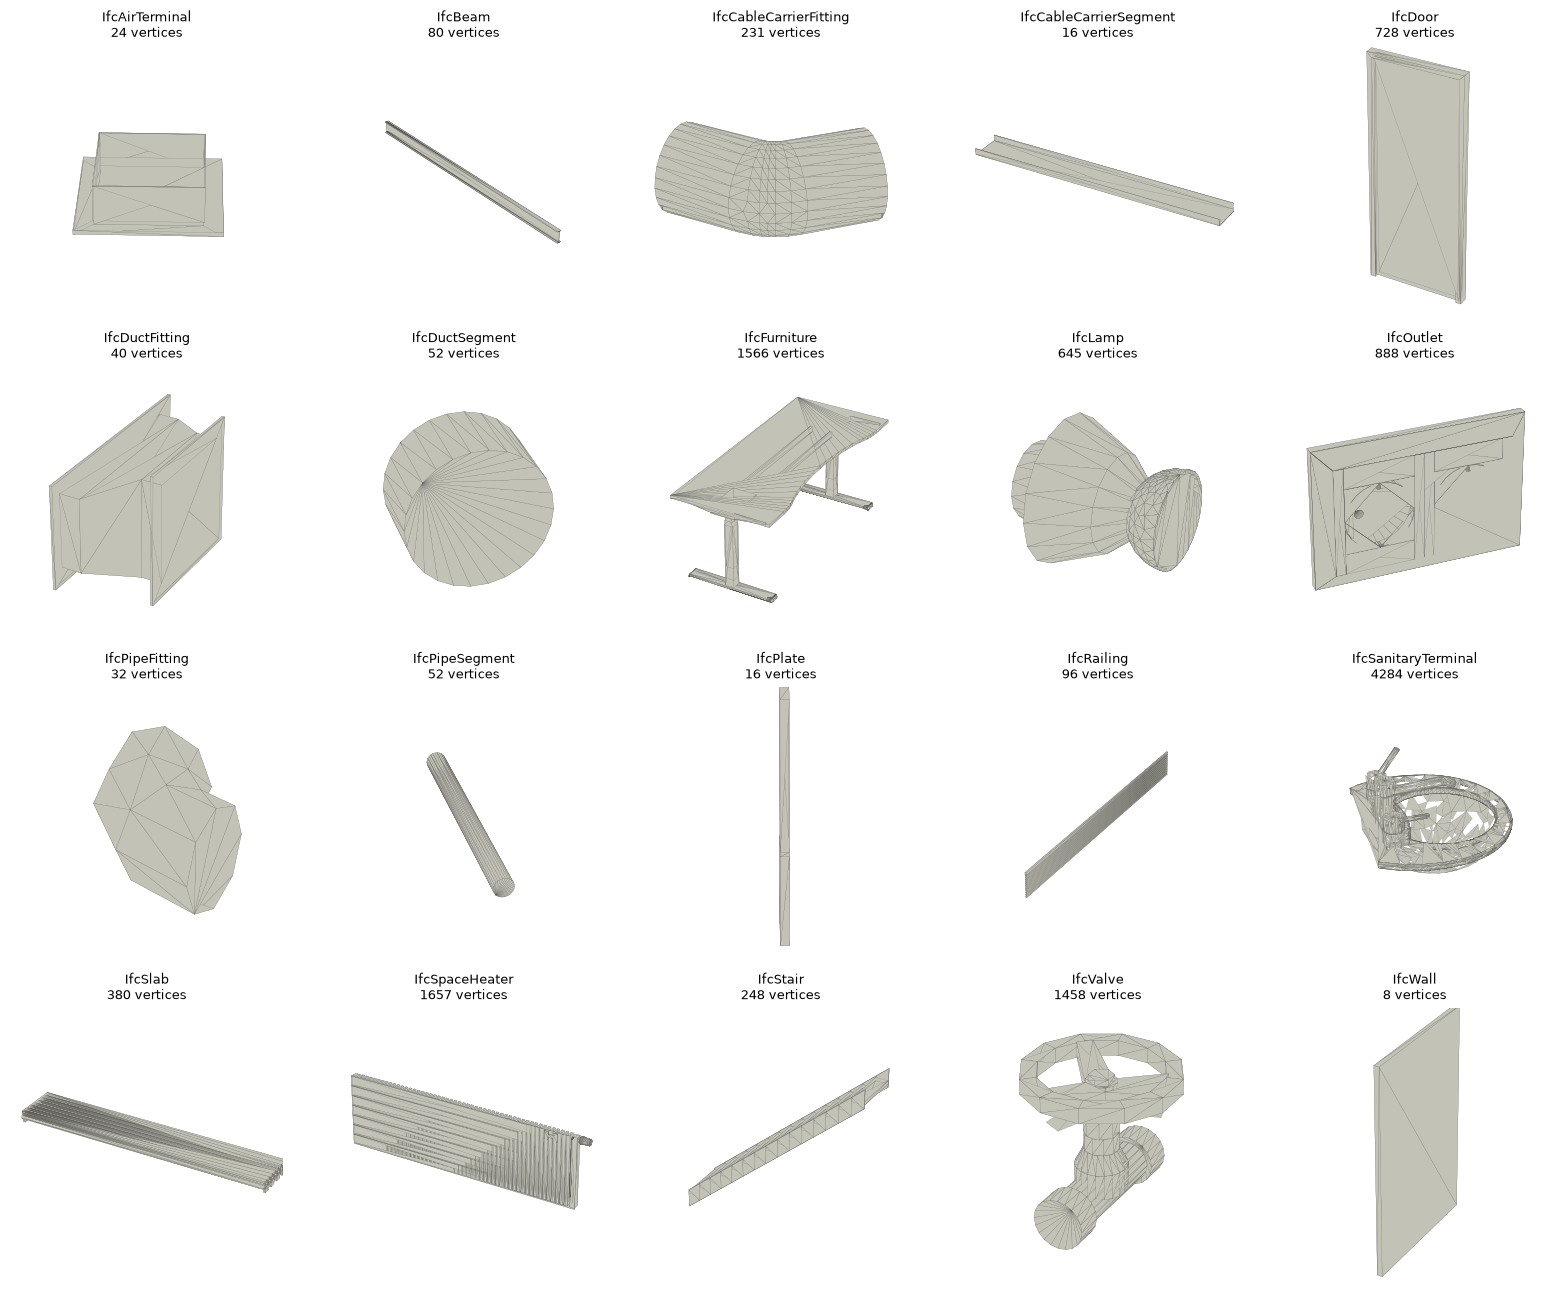

In [12]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

draw_rng = np.random.default_rng(SEED)
fig = plt.figure(figsize=(16, 13))
for i, (cls, (v, f)) in enumerate(sorted(meshes.items())):
    if len(f) > 4000:
        f = f[draw_rng.choice(len(f), 4000, replace=False)]
    ax = fig.add_subplot(4, 5, i + 1, projection="3d")
    ax.add_collection3d(Poly3DCollection(v[f], facecolor="#c3c2b7", edgecolor="#52514e", linewidths=0.1))
    lo, hi = v.min(axis=0), v.max(axis=0)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(np.maximum(hi - lo, 1e-3))     # true proportions
    ax.set_title(f"{cls}\n{len(v)} vertices", fontsize=9)
    ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "ifc_02_meshes.png", dpi=120)
plt.show()

### 3.2 World or local coordinates?

IfcOpenShell can give the mesh in two coordinate systems:
- **local**: the element's own system, as the authoring tool (Revit...) defined it;
- **world**: the element as it sits in the building.

Our first test used local coordinates and the wall came out **lying flat**, like a slab, because the wall's own "up" was not the z axis. Here we measure the bounding box of the same 20 objects in both systems. If the two boxes differ, the element was rotated in its building.

In [13]:
compare = []
for _, obj in test_objects.iterrows():
    v_local, _ = ifc_to_mesh(DATA / obj["path"], SETTINGS_LOCAL)
    v_world, _ = ifc_to_mesh(DATA / obj["path"], SETTINGS_WORLD)
    compare.append({
        "ifc_class": obj["ifc_class"],
        "local_bbox_m": np.round(v_local.max(0) - v_local.min(0), 2).tolist(),
        "world_bbox_m": np.round(v_world.max(0) - v_world.min(0), 2).tolist(),
    })
compare = pd.DataFrame(compare)
compare["differs"] = compare["local_bbox_m"] != compare["world_bbox_m"]
print("objects whose box changes between local and world:", compare["differs"].sum(), "/", len(compare))
compare[compare["differs"]]

objects whose box changes between local and world: 10 / 20


,ifc_class,local_bbox_m,world_bbox_m,differs
0,IfcAirTerminal,"[0.17, 0.17, 0.05]","[0.23, 0.23, 0.05]",True
1,IfcBeam,"[9.97, 0.15, 0.45]","[9.31, 3.88, 0.45]",True
6,IfcDuctSegment,"[0.1, 0.06, 0.1]","[0.11, 0.11, 0.1]",True
7,IfcFurniture,"[1.8, 0.8, 0.73]","[0.8, 1.8, 0.73]",True
8,IfcLamp,"[0.61, 0.61, 0.67]","[0.67, 0.61, 0.61]",True
9,IfcOutlet,"[0.12, 0.01, 0.09]","[0.08, 0.1, 0.09]",True
12,IfcPlate,"[0.77, 0.11, 0.02]","[0.08, 0.11, 0.77]",True
14,IfcSanitaryTerminal,"[0.43, 0.36, 0.23]","[0.44, 0.45, 0.23]",True
18,IfcValve,"[0.08, 0.07, 0.07]","[0.07, 0.08, 0.07]",True
19,IfcWall,"[4.16, 2.74, 0.1]","[0.1, 2.74, 4.16]",True


**Decision: world coordinates.**
- In local coordinates the "up" direction is not reliable: the wall (`[4.16, 2.74, 0.1]`) and the plate lie flat. A lying wall looks like a slab, exactly the kind of confusion we want to avoid.
- In world coordinates the z axis is the real vertical of the building (the wall becomes `[0.1, 2.74, 4.16]`, standing). Up and down carry architectural meaning: walls stand, slabs lie.
- What stays arbitrary in world coordinates is the **rotation in plan** (around the vertical axis): the beam runs diagonally. The training notebook can handle this by rotating each object randomly around the vertical axis during training (data augmentation), without changing the dataset.

The figure in 3.1 above already uses world coordinates.

## 4. The conversion module `src/ifc_graph.py`

The conversion code lives in a Python file, `01_autoencoder/src/ifc_graph.py`, not only in this notebook. The reason: the model server must apply **exactly the same preprocessing** to a new IFC file as we apply here. If both import the same functions, they cannot drift apart.

The module has one small function per step:

| Function | Input -> output | Why |
|---|---|---|
| `ifc_to_mesh(path)` | IFC file -> vertices `[V, 3]`, triangles `[F, 3]` | geometry in metres, world coordinates (section 3) |
| `sample_points(vertices, faces)` | mesh -> 1,024 points `[1024, 3]` | spread over the surface by triangle area, so a wall with 8 vertices still gets 1,024 points; fixed seed |
| `normalize_points(points)` | points -> points centred at 0, inside a sphere of radius 1, plus the original radius in metres | the model should compare shapes, not positions or sizes |
| `knn_edges(points)` | points -> `edge_index` `[2, 1024 x 16]` | links each point to its 16 nearest points (the graph edges) |
| `to_pyg_data(...)` | arrays -> PyTorch Geometric `Data` | the format the graph network reads |
| `ifc_to_graph(path)` | IFC file -> `Data` | all steps in one call |

**Agreed settings:** 1,024 points per object, k = 16 neighbours, seed 42, world coordinates.

**Two implementation notes.**
- The nearest neighbours are found with SciPy (`cKDTree`), not with PyTorch Geometric's `knn_graph`, because the latter needs an extra compiled package (`pyg-lib`) that is not installed. The result is the same kind of graph.
- Everything up to the arrays uses only NumPy, SciPy, trimesh and IfcOpenShell, so the server can build the graph without PyTorch if it runs the model with ONNX.

**What is stored in each graph:** `x` (the normalised coordinates, the model input), `pos` (the same coordinates under PyG's usual name, used by geometric transforms such as rotations), `edge_index`, plus `object_id` and `scale` for information only. **The IFC class is not stored in the graph**; it stays in the split file, used only for evaluation.

We add the `src` folder to Python's search path so the notebook can import the module, and we hide one harmless warning that PyTorch Geometric prints about a deprecated PyTorch feature.

In [14]:
import sys
import warnings
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")   # harmless, from torch_geometric

sys.path.insert(0, str(Path("../src")))
import ifc_graph
import torch
import torch_geometric
from torch_geometric.utils import contains_self_loops, degree

print("torch", torch.__version__, "| torch_geometric", torch_geometric.__version__)
print("N_POINTS =", ifc_graph.N_POINTS, "| K_NEIGHBOURS =", ifc_graph.K_NEIGHBOURS, "| SEED =", ifc_graph.SEED)

/opt/anaconda3/envs/Hackathon/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1 | torch_geometric 2.8.1
N_POINTS = 1024 | K_NEIGHBOURS = 16 | SEED = 42


### 4.1 Check the module on the 20 test objects

We convert the same 20 objects (one per class) into graphs and check, for each one:
- **shapes**: `x` is `[1024, 3]` and `edge_index` is `[2, 16384]` (1,024 points x 16 neighbours);
- **no self-loops**: no point is linked to itself;
- **in-degree 16**: every point receives exactly 16 links;
- **normalisation**: the mean of the points is about 0 and the farthest point is at distance 1;
- **reproducible**: converting the same file twice gives exactly the same graph.

`scale_m` is the radius of the original object in metres, removed by the normalisation (information only).

In [15]:
checks, graphs = [], {}
for _, obj in test_objects.iterrows():
    g = ifc_graph.ifc_to_graph(DATA / obj["path"])
    g_again = ifc_graph.ifc_to_graph(DATA / obj["path"])
    in_degree = degree(g.edge_index[1], g.num_nodes)
    checks.append({
        "ifc_class": obj["ifc_class"],
        "x": list(g.x.shape),
        "edge_index": list(g.edge_index.shape),
        "self_loops": contains_self_loops(g.edge_index),
        "in_degree_16": bool((in_degree == ifc_graph.K_NEIGHBOURS).all()),
        "max_abs_mean": round(float(g.x.mean(0).abs().max()), 6),
        "max_radius": round(float(g.x.norm(dim=1).max()), 4),
        "reproducible": bool(torch.equal(g.x, g_again.x) and torch.equal(g.edge_index, g_again.edge_index)),
        "scale_m": round(float(g.scale), 2),
    })
    graphs[obj["ifc_class"]] = g
checks = pd.DataFrame(checks)

assert (checks["x"].apply(tuple) == (1024, 3)).all()
assert (checks["edge_index"].apply(tuple) == (2, 1024 * 16)).all()
assert not checks["self_loops"].any() and checks["in_degree_16"].all() and checks["reproducible"].all()
print("all module checks passed")
checks

all module checks passed


,ifc_class,x,edge_index,self_loops,in_degree_16,max_abs_mean,max_radius,reproducible,scale_m
0,IfcAirTerminal,"[1024, 3]","[2, 16384]",False,True,0.000000,1.0,True,0.12
1,IfcBeam,"[1024, 3]","[2, 16384]",False,True,0.000000,1.0,True,5.06
2,IfcCableCarrierFitting,"[1024, 3]","[2, 16384]",False,True,0.000000,1.0,True,0.15
3,IfcCableCarrierSegment,"[1024, 3]","[2, 16384]",False,True,0.000005,1.0,True,1.27
4,IfcDoor,"[1024, 3]","[2, 16384]",False,True,0.000000,1.0,True,1.18
5,IfcDuctFitting,"[1024, 3]","[2, 16384]",False,True,0.000000,1.0,True,0.24
6,IfcDuctSegment,"[1024, 3]","[2, 16384]",False,True,0.000000,1.0,True,0.06
7,IfcFurniture,"[1024, 3]","[2, 16384]",False,True,0.000000,1.0,True,1.04
8,IfcLamp,"[1024, 3]","[2, 16384]",False,True,0.000000,1.0,True,0.41
9,IfcOutlet,"[1024, 3]","[2, 16384]",False,True,0.000000,1.0,True,0.08


One converted graph, as the model will receive it:

In [16]:
example = graphs["IfcDoor"]
print(example)
print("\nfirst 3 nodes (x, y, z):\n", example.x[:3])
print("\nfirst 5 edges (neighbour -> point):\n", example.edge_index[:, :5])

Data(x=[1024, 3], edge_index=[2, 16384], pos=[1024, 3], object_id='b521796d030f4d8c9884dcfdf54433d0', scale=[1])

first 3 nodes (x, y, z):
 tensor([[-0.3532, -0.0148, -0.3909],
        [-0.0997, -0.0148,  0.2971],
        [ 0.3694,  0.0057, -0.6713]])

first 5 edges (neighbour -> point):
 tensor([[105, 264, 630, 719, 411],
        [  0,   0,   0,   0,   0]])


## 5. Look at the graphs

The checks above say the numbers are right, but not that the graph still **looks like the object**. We draw six graphs of very different shapes: each dot is a node (one of the 1,024 points) and each thin line is an edge (a link to one of its 16 nearest points). All objects are now normalised, so they all fit in the same sphere of radius 1.

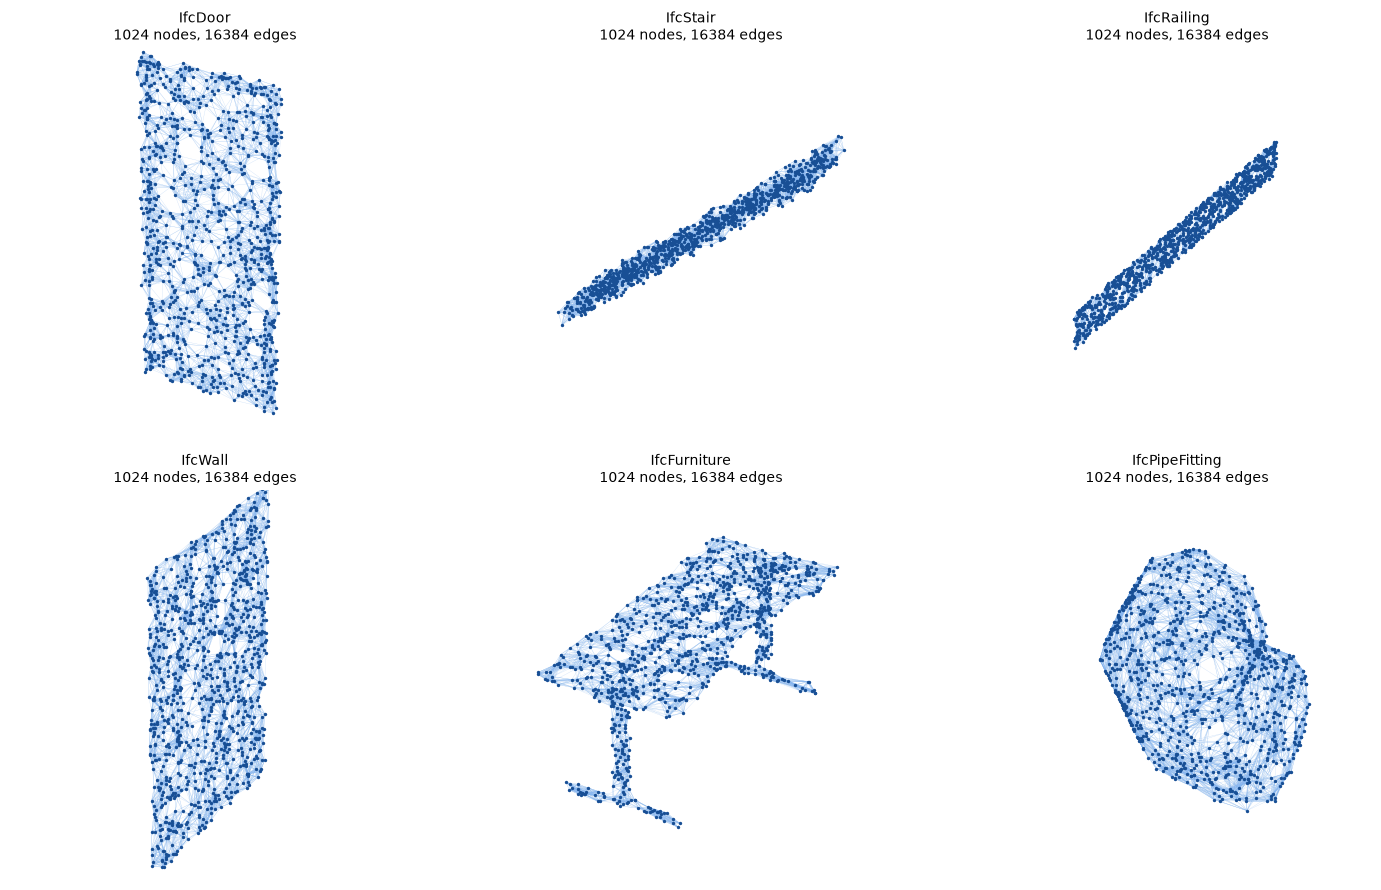

In [17]:
from mpl_toolkits.mplot3d.art3d import Line3DCollection

SHOW = ["IfcDoor", "IfcStair", "IfcRailing", "IfcWall", "IfcFurniture", "IfcPipeFitting"]

fig = plt.figure(figsize=(15, 9))
for i, cls in enumerate(SHOW):
    g = graphs[cls]
    p = g.pos.numpy()
    src, dst = g.edge_index.numpy()
    ax = fig.add_subplot(2, 3, i + 1, projection="3d")
    ax.add_collection3d(Line3DCollection(np.stack([p[src], p[dst]], axis=1),
                                         colors="#86b6ef", linewidths=0.2, alpha=0.5))
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=2, color="#184f95", depthshade=False)
    lo, hi = p.min(axis=0), p.max(axis=0)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(np.maximum(hi - lo, 1e-2))      # true proportions
    ax.set_title(f"{cls}\n{g.num_nodes} nodes, {g.num_edges} edges", fontsize=10)
    ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "ifc_03_graphs.png", dpi=130)
plt.show()

In the 3D view the stair and the railing look like plain elongated bands. That is only the viewing angle: below we draw their points from the **side**, along their longest horizontal direction and the vertical axis. The stair keeps its **steps**, and the railing is simply very long and low (about 12 m long, 1.15 m high), so its points are correct.

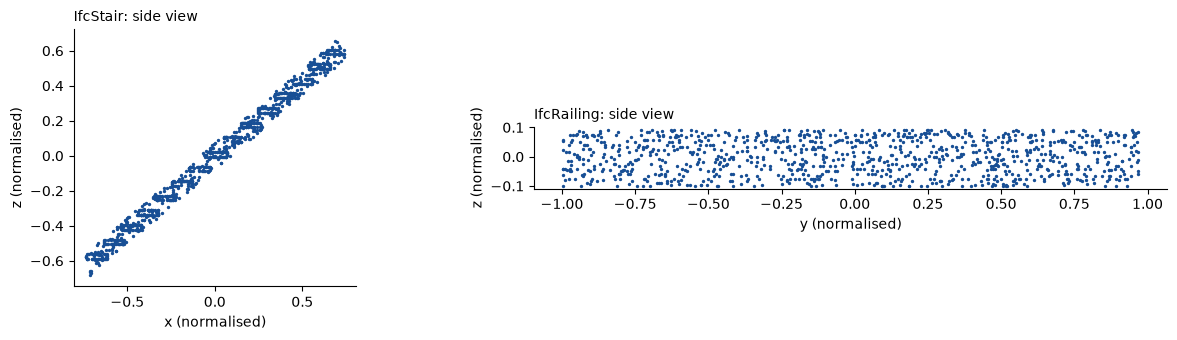

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, cls in zip(axes, ["IfcStair", "IfcRailing"]):
    p = graphs[cls].pos.numpy()
    long_axis = int(np.argmax(np.ptp(p[:, :2], axis=0)))   # longest horizontal direction (x or y)
    ax.scatter(p[:, long_axis], p[:, 2], s=2, color="#184f95")
    ax.set_aspect("equal")
    ax.set_title(f"{cls}: side view", loc="left", fontsize=10)
    ax.set_xlabel("xy"[long_axis] + " (normalised)")
    ax.set_ylabel("z (normalised)")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "ifc_04_side_views.png", dpi=130)
plt.show()

### 5.1 Is each graph in one piece?

A graph neural network passes information only along edges. If a graph splits into separate **pieces** (connected components), information cannot travel between them. This can happen for two reasons:
- the object really has separate parts (the legs of a table, the bars of a railing), which is fine;
- the number of neighbours `k` is too small to bridge gaps between parts, which we can fix by raising `k`.

We use **NetworkX** (a library for graphs) to count the pieces of each of the 20 test graphs, ignoring the direction of the edges. We count them for k = 8, 16 and 32 on the same points, to see whether our choice k = 16 is enough. We also report the share of points in the biggest piece.

In [19]:
import networkx as nx

def pieces(points, k):
    """Number of connected pieces and share of points in the biggest one, for a kNN graph."""
    src, dst = ifc_graph.knn_edges(points, k=k)
    G = nx.Graph()
    G.add_nodes_from(range(len(points)))
    G.add_edges_from(zip(src.tolist(), dst.tolist()))
    sizes = [len(c) for c in nx.connected_components(G)]
    return len(sizes), max(sizes) / len(points)

rows = []
for cls, g in graphs.items():
    row = {"ifc_class": cls}
    for k in [8, 16, 32]:
        n, biggest = pieces(g.pos.numpy(), k)
        row[f"pieces_k{k}"] = n
        row[f"biggest_share_k{k}"] = round(biggest, 3)
    rows.append(row)
components = pd.DataFrame(rows).set_index("ifc_class")
print("graphs in one piece:", {f"k={k}": int((components[f'pieces_k{k}'] == 1).sum()) for k in [8, 16, 32]}, "of", len(components))
components

graphs in one piece: {'k=8': 20, 'k=16': 20, 'k=32': 20} of 20


,pieces_k8,biggest_share_k8,pieces_k16,biggest_share_k16,pieces_k32,biggest_share_k32
ifc_class,,,,,,
IfcAirTerminal,1,1.0,1,1.0,1,1.0
IfcBeam,1,1.0,1,1.0,1,1.0
IfcCableCarrierFitting,1,1.0,1,1.0,1,1.0
IfcCableCarrierSegment,1,1.0,1,1.0,1,1.0
IfcDoor,1,1.0,1,1.0,1,1.0
IfcDuctFitting,1,1.0,1,1.0,1,1.0
IfcDuctSegment,1,1.0,1,1.0,1,1.0
IfcFurniture,1,1.0,1,1.0,1,1.0
IfcLamp,1,1.0,1,1.0,1,1.0


**Findings.**
- The graphs keep the recognisable shape of each object (door frame, table legs, stair steps).
- All 20 test graphs are in **one piece** already with k = 8, so k = 16 gives a margin; it is not too small. Even the table, whose legs are separate solids, stays connected because the points are dense enough to bridge the joints.
- This is only 20 objects. When we convert the whole dataset (next section) we count the pieces of every graph again.
- **Limitation:** 1,024 points is a fixed budget. For very long or very detailed objects (a 12 m railing, a washbasin with taps) small details get only a few points.

## 6. Convert the whole dataset

Now we run the module on all 7,930 objects, set by set (train, val, test), in the order of the split file.

- **Failures do not stop the run.** If one file cannot be converted, we store its id, class, set and error message, and continue.
- **Crash-safe.** Our first full run stopped at object 7,247: for one file IfcOpenShell's geometry engine (written in C++) crashed with a *segmentation fault*. Such a crash cannot be caught with `try/except`; it kills the whole notebook kernel. So the conversion runs in a separate **worker process** (`ifc_graph.SafeConverter`). If the worker crashes, or takes more than 120 s on one file, only that file is marked as failed (`crash` or `timeout`), a new worker starts, and the notebook keeps running. The model server can use the same protection. The split file is **not** changed; failed objects are simply missing from the graph files and listed in `failures.csv`.
- **What is saved.** To keep the files small, we save only the normalised points (about 12 KB per object, about 100 MB in total instead of about 2.2 GB with the edges). The edges are rebuilt when loading, with the same `knn_edges` function the server uses (about 12 seconds for the whole dataset). The settings used (1,024 points, k = 16, seed 42, world coordinates...) are saved inside each file.
- **Where.** `data/ifc_graphs/` (git-ignored, never uploaded):
  `train.pt`, `val.pt`, `test.pt` and `failures.csv`.
- **Cache.** The conversion takes several minutes. If the files already exist, the notebook loads them instead of converting again. Set `REBUILD = True` to force a new conversion (for example after changing the module).

In [20]:
GRAPH_DIR = DATA / "ifc_graphs"
GRAPH_FILES = {s: GRAPH_DIR / f"{s}.pt" for s in ["train", "val", "test"]}
FAILURES_FILE = GRAPH_DIR / "failures.csv"
REBUILD = False

already_built = all(f.exists() for f in GRAPH_FILES.values()) and FAILURES_FILE.exists()
if already_built and not REBUILD:
    print("graph files found in", GRAPH_DIR, "-> not converting again (set REBUILD = True to force it)")
    failures = pd.read_csv(FAILURES_FILE)
else:
    t_start = time.time()
    failures = []
    for s in ["train", "val", "test"]:
        rows_s = split[split["split"] == s]
        points, ids, scales = [], [], []
        with ifc_graph.SafeConverter(timeout=120) as converter:
            for n, obj in enumerate(rows_s.itertuples(), start=1):
                status, result, scale = converter.convert(DATA / obj.path)
                if status == "ok":
                    points.append(result); ids.append(obj.object_id); scales.append(scale)
                else:   # "error", "crash" or "timeout": keep the reason, skip the object
                    failures.append({"object_id": obj.object_id, "ifc_class": obj.ifc_class,
                                     "split": s, "status": status, "error": result})
                if n % 1000 == 0:
                    print(f"  {s}: {n} / {len(rows_s)}   ({time.time() - t_start:.0f} s)")
        ifc_graph.save_points_file(GRAPH_FILES[s], points, ids, scales)
        print(f"{s}: saved {len(ids)} graphs to {GRAPH_FILES[s]}")
    failures = pd.DataFrame(failures, columns=["object_id", "ifc_class", "split", "status", "error"])
    failures.to_csv(FAILURES_FILE, index=False)
    print(f"conversion time: {(time.time() - t_start) / 60:.1f} min")

graph files found in ../../data/ifc_graphs -> not converting again (set REBUILD = True to force it)


### 6.1 How many objects failed, and why

We count the failures per class and per set, and group them by error message. A class with many failures would be a problem for the anomaly or similarity tests.

In [21]:
print(f"failed: {len(failures)} of {len(split)} objects ({len(failures) / len(split):.2%})")
if len(failures):
    print("\nper set:", failures["split"].value_counts().to_dict())
    print("\nper class:")
    print(failures["ifc_class"].value_counts().to_string())
    print("\nerror messages:")
    print(failures["error"].str.slice(0, 120).value_counts().to_string())

failed: 3 of 7930 objects (0.04%)

per set: {'train': 2, 'test': 1}

per class:
ifc_class
IfcPlate    2
IfcValve    1

error messages:
error
RuntimeError: Failed to process shape. Product: #60=IfcPlate('0SKGGkH0nFSBCdyoOACHeD',#5,'FINPLATE','PLT12*190','PLT12*1    1
worker process crashed (exit code -11)                                                                                      1
RuntimeError: Failed to process shape. Product: #60=IfcPlate('2jor$Mffz70gG9e1enAw$_',#5,'FINPLATE','PLT12*190','PLT12*1    1


### 6.2 Load the saved dataset and check it

We load the files **exactly as the training code will**, with `ifc_graph.load_graphs`, and check:
- each file contains exactly the objects of its set in the split file, minus the failed ones (no object lost, none in the wrong set);
- every graph has `x` of shape `[1024, 3]` and `edge_index` of shape `[2, 16384]`;
- no coordinate is NaN or infinite.

In [22]:
t0 = time.time()
datasets = {s: ifc_graph.load_graphs(f) for s, f in GRAPH_FILES.items()}
print(f"loaded in {time.time() - t0:.0f} s")

for s, gs in datasets.items():
    expected = set(split.loc[split["split"] == s, "object_id"]) - set(failures.loc[failures["split"] == s, "object_id"])
    assert [g.object_id for g in gs] == [i for i in split.loc[split["split"] == s, "object_id"] if i in expected]
    size_mb = GRAPH_FILES[s].stat().st_size / 1e6
    print(f"{s:5s}: {len(gs):5d} graphs   file {size_mb:.0f} MB")

all_graphs = [g for gs in datasets.values() for g in gs]
assert all(tuple(g.x.shape) == (1024, 3) for g in all_graphs)
assert all(tuple(g.edge_index.shape) == (2, 1024 * 16) for g in all_graphs)
assert all(torch.isfinite(g.x).all() for g in all_graphs)
print("all dataset checks passed:", len(all_graphs), "graphs, same order as the split file")
print("settings stored in the files:", torch.load(GRAPH_FILES["train"], weights_only=True)["preprocessing"])

loaded in 15 s
train:  4716 graphs   file 58 MB
val  :   833 graphs   file 10 MB
test :  2378 graphs   file 29 MB
all dataset checks passed: 7927 graphs, same order as the split file
settings stored in the files: {'n_points': 1024, 'k_neighbours': 16, 'seed': 42, 'coordinates': 'world (IfcOpenShell use-world-coords), metres', 'sampling': 'area-weighted uniform surface sampling (trimesh.sample.sample_surface)', 'normalisation': 'centre = mean of points, divide by max distance (unit sphere)', 'edges': 'directed kNN, row 0 = neighbour, row 1 = point, no self-loops', 'ifcopenshell': '0.9.0.post1'}


### 6.3 Is every graph in one piece? (whole dataset)

We repeat the "pieces" check of section 5.1 on all graphs. NetworkX would take several minutes for 7,930 graphs, so we use SciPy's `connected_components`, which counts the same thing much faster (we first confirm it gives the same answer as NetworkX on the 20 test graphs). The direction of the edges is ignored (`connection="weak"`).

In [23]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def n_pieces(g):
    src, dst = g.edge_index.numpy()
    adjacency = coo_matrix((np.ones(len(src)), (src, dst)), shape=(g.num_nodes, g.num_nodes))
    return connected_components(adjacency, directed=True, connection="weak")[0]

assert all(n_pieces(g) == components.loc[cls, "pieces_k16"] for cls, g in graphs.items())   # same as NetworkX

class_of = dict(zip(split["object_id"], split["ifc_class"]))
pieces_all = pd.DataFrame({"ifc_class": [class_of[g.object_id] for g in all_graphs],
                           "pieces": [n_pieces(g) for g in all_graphs]})
print(f"graphs in one piece: {(pieces_all['pieces'] == 1).sum()} / {len(pieces_all)}")
pieces_all.groupby("ifc_class")["pieces"].agg(
    one_piece_share=lambda s: round((s == 1).mean(), 3), max_pieces="max")

graphs in one piece: 7806 / 7927


,one_piece_share,max_pieces
ifc_class,,
IfcAirTerminal,1.000,1
IfcBeam,0.965,3
IfcCableCarrierFitting,0.969,2
IfcCableCarrierSegment,1.000,1
IfcDoor,0.994,2
IfcDuctFitting,1.000,1
IfcDuctSegment,1.000,1
IfcFurniture,0.996,2
IfcLamp,1.000,1


Some graphs are in more than one piece. Is k = 16 too small for them, or do these objects really have separate parts? We re-count their pieces with k = 32 (twice as many neighbours) and look at the size of their smallest piece. If doubling k barely helps and the pieces are large, they are real separate parts of the object (for example taps modelled apart from a washbasin), not a gap that more neighbours would bridge.

In [24]:
multi = [(cls_, g) for cls_, g in zip(pieces_all["ifc_class"], all_graphs) if n_pieces(g) > 1]
rows = []
for cls_, g in multi:
    p = g.pos.numpy()
    src, dst = ifc_graph.knn_edges(p, k=32)
    n32 = connected_components(coo_matrix((np.ones(len(src)), (src, dst)), shape=(len(p), len(p))),
                               directed=True, connection="weak")[0]
    labels = connected_components(coo_matrix((np.ones(g.num_edges), tuple(g.edge_index.numpy())),
                                             shape=(len(p), len(p))), directed=True, connection="weak")[1]
    rows.append({"ifc_class": cls_, "still_split_k32": n32 > 1, "smallest_piece_points": np.bincount(labels).min()})
multi = pd.DataFrame(rows)
print(f"graphs in several pieces with k=16: {len(multi)}")
print(f"still in several pieces with k=32:  {multi['still_split_k32'].sum()}")
print(f"median size of the smallest piece:  {multi['smallest_piece_points'].median():.0f} points (of 1,024)")

graphs in several pieces with k=16: 121
still in several pieces with k=32:  101
median size of the smallest piece:  168 points (of 1,024)


### 6.4 A few examples

Three graphs from the train set, as the model receives them. The class is looked up in the split file only to make the printout readable; it is not inside the graph.

In [25]:
for g in datasets["train"][::1500][:3]:
    print(class_of[g.object_id], "->", g)
    print("   first node:", g.x[0].numpy().round(3), "| scale:", round(float(g.scale), 2), "m")

IfcAirTerminal -> Data(x=[1024, 3], edge_index=[2, 16384], pos=[1024, 3], object_id='0006599ce0b2431ba182128c65bb51b8', scale=[1])
   first node: [-0.087  0.299 -0.126] | scale: 0.41 m
IfcDuctFitting -> Data(x=[1024, 3], edge_index=[2, 16384], pos=[1024, 3], object_id='a12eb28c6b8a47498061a9f032a90e82', scale=[1])
   first node: [0.776 0.14  0.158] | scale: 0.45 m
IfcPlate -> Data(x=[1024, 3], edge_index=[2, 16384], pos=[1024, 3], object_id='23ee847202f6493a969b32049437398d', scale=[1])
   first node: [ 0.145  0.375 -0.004] | scale: 0.78 m


### 6.5 Findings

- **7,927 of 7,930 objects converted (99.96 %).** The conversion took about 11 minutes on a laptop CPU (first run; later runs load the saved files).
- **3 failures**, listed in `data/ifc_graphs/failures.csv`:
  - 2 `IfcPlate` (1 train, 1 test): IfcOpenShell could not build the shape (`RuntimeError: Failed to process shape`). Both are the same kind of steel fin plate.
  - 1 `IfcValve` (train): the geometry engine **crashed** (segmentation fault). The crash-safe worker caught it and the run continued.
  - No class loses more than 2 objects, so the failures do not affect the split balance.
- **Saved dataset:** `train.pt` 4,716 graphs, `val.pt` 833, `test.pt` 2,378. About 97 MB in total. Loading all three files and rebuilding the edges takes about 15 seconds.
- **Every graph** has `x` `[1024, 3]` and `edge_index` `[2, 16384]`, no NaN, and the files follow the order of the split file.
- **Pieces:** 7,806 of 7,927 graphs (98.5 %) are in one piece. The rest are mostly washbasins (`IfcSanitaryTerminal`). Doubling k to 32 merges very few of them and their pieces are large, so they are real separate parts of the objects, not a problem of k. **We keep k = 16.**

## 7. How one IFC element becomes a tensor

This section explains, in plain words, what the graph network will actually receive. We follow one door from its IFC file to the two tensors (tables of numbers) stored for it.

### Step 1. IFC file -> triangle mesh
An IFC file does not contain a shape you can draw directly. It contains a **recipe**: "take this rectangle, extrude it 2.1 m, cut this opening, place it here". IfcOpenShell runs the recipe and returns a **triangle mesh**: a list of corner points (vertices) and a list of triangles that connect them. We ask for it in metres and in building coordinates, so "up" is the real vertical.

### Step 2. Mesh -> 1,024 points
Meshes are very different from each other: a wall can have 8 vertices, a washbasin thousands. A neural network prefers inputs of the **same size**, so we place exactly **1,024 points** on the surface of every object. Big triangles get more points than small ones, so the points cover the surface evenly. A fixed seed makes the points the same every time.

### Step 3. Centre and scale
We move the points so their average is at (0, 0, 0) and shrink or enlarge them so the farthest point is at distance 1. Now a small door and a big door with the same proportions give the same points: the model compares **shapes**, not sizes or positions. (The original size is kept apart as `scale`, for information only.)

### Step 4. The nodes tensor `x`, shape `[1024, 3]`
This is a table with **1,024 rows and 3 columns**. Each row is one point (one **node** of the graph); the columns are its x, y and z coordinates. The table below shows the first 5 rows for our door. The order of the rows has no meaning: shuffling them would describe the same door.

In [26]:
door = graphs["IfcDoor"]
print("x shape:", tuple(door.x.shape), "-> 1,024 nodes, 3 numbers each (x, y, z)")
pd.DataFrame(door.x[:5].numpy(), columns=["x", "y", "z"]).round(3).rename_axis("node")

x shape: (1024, 3) -> 1,024 nodes, 3 numbers each (x, y, z)


,x,y,z
node,,,
0,-0.353,-0.015,-0.391
1,-0.100,-0.015,0.297
2,0.369,0.006,-0.671
3,-0.159,-0.015,-0.146
4,0.276,0.023,-0.185


### Step 5. The edge list `edge_index`, shape `[2, 16384]`
The points alone are a **point cloud**. To make a **graph**, we link every point to its 16 nearest points. These links are the **edges**: they tell the network which points are neighbours, so it can learn local shape (a flat face, an edge, a curve).

`edge_index` stores the edges as a table with **2 rows**. Each **column** is one arrow:
- row 0: the neighbour the arrow starts from (source);
- row 1: the point the arrow arrives at (target).

Every point receives 16 arrows, so there are 1,024 x 16 = **16,384 columns**. The arrows are stored point after point: the first 16 columns are the 16 neighbours of node 0, the next 16 those of node 1, and so on. Below are the 16 arrows that arrive at node 0 of the door.

In [27]:
print("edge_index shape:", tuple(door.edge_index.shape), "-> 2 rows, one column per arrow")
pd.DataFrame(door.edge_index[:, :16].numpy(), index=["source (neighbour)", "target (point)"])

edge_index shape: (2, 16384) -> 2 rows, one column per arrow


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
source (neighbour),105,264,630,719,411,612,169,556,781,603,445,307,611,638,529,802
target (point),0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### A tiny example you can see
With 1,024 points the graph is too dense to read, so here is the same idea with **6 points** and **2 neighbours** each, using the very same function (`ifc_graph.knn_edges`) as the real dataset. The points lie on a flat plane (z = 0) so we can draw them in 2D.

The drawing shows each node with its number, and an arrow from each neighbour to the point it belongs to. When two points are each other's nearest neighbours, you see two arrows between them, one in each direction. When only one arrow connects two points, the link goes one way: A is among B's 2 nearest points, but B is not among A's.

x (6 nodes x 3 coordinates):
        x    y    z
node               
0     0.0  0.0  0.0
1     1.0  0.0  0.0
2     2.2  0.0  0.0
3     0.0  1.3  0.0
4     0.0  2.7  0.0
5     1.4  1.6  0.0

edge_index (2 rows x 6*2 = 12 arrows):
        0   1   2   3   4   5   6   7   8   9   10  11
source   1   3   0   2   1   5   0   4   3   5   3   1
target   0   0   1   1   2   2   3   3   4   4   5   5

read as arrows: 1->0, 3->0, 0->1, 2->1, 1->2, 5->2, 0->3, 4->3, 3->4, 5->4, 3->5, 1->5


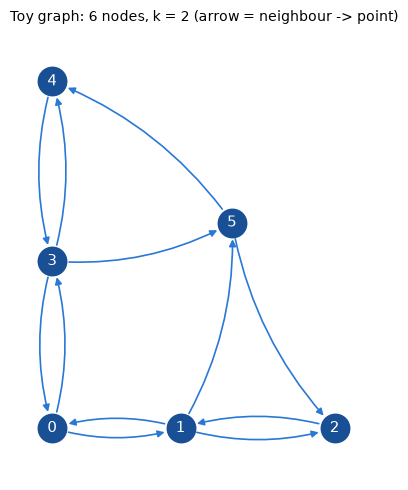

In [28]:
toy_x = np.array([[0.0, 0.0, 0.0],
                  [1.0, 0.0, 0.0],
                  [2.2, 0.0, 0.0],
                  [0.0, 1.3, 0.0],
                  [0.0, 2.7, 0.0],
                  [1.4, 1.6, 0.0]], dtype=np.float32)
toy_edges = ifc_graph.knn_edges(toy_x, k=2)

print("x (6 nodes x 3 coordinates):")
print(pd.DataFrame(toy_x, columns=["x", "y", "z"]).rename_axis("node").to_string())
print("\nedge_index (2 rows x 6*2 = 12 arrows):")
print(pd.DataFrame(toy_edges, index=["source", "target"]).to_string())
print("\nread as arrows:", ", ".join(f"{s}->{t}" for s, t in toy_edges.T))

fig, ax = plt.subplots(figsize=(5.5, 5))
for s, t in toy_edges.T:
    ax.annotate("", xy=toy_x[t, :2], xytext=toy_x[s, :2],
                arrowprops=dict(arrowstyle="-|>", color="#2a78d6", lw=1.2, shrinkA=12, shrinkB=12,
                                connectionstyle="arc3,rad=0.15"))
ax.scatter(toy_x[:, 0], toy_x[:, 1], s=420, color="#184f95", zorder=3)
for i, (px, py, _) in enumerate(toy_x):
    ax.text(px, py, str(i), color="white", ha="center", va="center", fontsize=11, zorder=4)
ax.set_title("Toy graph: 6 nodes, k = 2 (arrow = neighbour -> point)", loc="left", fontsize=10)
ax.set_aspect("equal"); ax.margins(0.15); ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "ifc_05_toy_graph.png", dpi=130)
plt.show()

### What is NOT inside the tensors
- **No IFC class** (door, wall...), **no name** and **no properties** (material, manufacturer, Pset values). If the model could see them, it would "cheat": similarity and anomaly results would come from the label, not from the geometry. The class is kept only in the split file, to stratify the split and to evaluate results (for example, "are the 5 most similar objects of the same class?").
- **No absolute size or position.** They are removed by the normalisation; the original radius is stored apart as `scale`, which is not a model input.

### In one sentence
**One IFC element = 1,024 points on its surface (`x`, `[1024, 3]`) + 16,384 arrows linking each point to its 16 nearest points (`edge_index`, `[2, 16384]`).**

## 8. geometry-only GCN autoencoder

This section uses the graphs created above. The model receives only normalised XYZ coordinates and kNN edges; IFC class, object name, properties and scale remain outside the model. We use a GCN encoder, global pooling, a 32-dimensional latent vector and an MLP decoder.

In [29]:
# Section 8 can run on its own (e.g. after a kernel restart): it loads what it needs here.
import sys, random, importlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch_geometric.loader import DataLoader
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")   # harmless, from torch_geometric

SRC = str(Path("../src").resolve())
if SRC not in sys.path:
    sys.path.insert(0, SRC)
import graph_autoencoder
importlib.reload(graph_autoencoder)   # always use the latest version of the file
from graph_autoencoder import GraphAutoencoder, LazyGraphDataset, chamfer_distance

SEED = 42
random.seed(SEED); np.random.seed(SEED)
split = pd.read_csv("../splits/ifc_split.csv")   # saved in section 2

torch.manual_seed(SEED)
DEVICE = torch.device('cpu')
ANOMALY_CLASSES = {'IfcStair', 'IfcRailing'}
class_of = dict(zip(split['object_id'], split['ifc_class']))
train_ids = set(split.loc[(split['split'] == 'train') & ~split['ifc_class'].isin(ANOMALY_CLASSES), 'object_id'])
val_ids = set(split.loc[split['split'] == 'val', 'object_id'])
globals().pop('datasets', None)  # free memory if section 6.2 was run; safe if it was not
train_graphs = LazyGraphDataset('../../data/ifc_graphs/train.pt', train_ids)
val_graphs = LazyGraphDataset('../../data/ifc_graphs/val.pt', val_ids)
loader = DataLoader(train_graphs, batch_size=4, shuffle=True, generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_graphs, batch_size=4, shuffle=False)
print(len(train_graphs), len(val_graphs), train_graphs[0].x.shape, train_graphs[0].edge_index.shape)

4434 833 torch.Size([1024, 3]) torch.Size([2, 16384])


### 8.1 Model and loss

Three graph convolution layers aggregate local geometry, then global mean pooling creates one vector per object. The decoder reconstructs all 1,024 points. To keep CPU memory practical, Chamfer loss uses a fixed 256-point subset during this first experiment.

In [30]:
model = GraphAutoencoder(latent_dim=32, hidden_dim=64).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
LOSS_POINTS = 256
print('parameters:', sum(p.numel() for p in model.parameters()))

parameters: 1745184


### 8.2 Train and save the best checkpoint

We monitor validation Chamfer distance and save only the best model under the ignored `data/` directory.

In [31]:
def run_epoch(graph_loader, training):
    model.train(training); total = 0.0
    for data in graph_loader:
        data = data.to(DEVICE)
        target = data.pos.reshape(-1, 1024, 3)[:, :LOSS_POINTS]
        if training: optimizer.zero_grad()
        pred, _ = model(data)
        loss = chamfer_distance(pred[:, :LOSS_POINTS], target)
        if training:
            loss.backward(); optimizer.step()
        total += loss.item() * data.num_graphs
    return total / len(graph_loader.dataset)

history = []
best = float('inf')
for epoch in range(1, 31):
    train_loss = run_epoch(loader, True)
    val_loss = run_epoch(val_loader, False)
    history.append({'epoch': epoch, 'train_chamfer': train_loss, 'val_chamfer': val_loss})
    if val_loss < best:
        best = val_loss
        torch.save({'model': model.state_dict(), 'latent_dim': 32, 'loss_points': LOSS_POINTS}, '../../data/gcn_autoencoder.pt')
    print(f'{epoch:02d}: train={train_loss:.6f} val={val_loss:.6f}')
pd.DataFrame(history)

01: train=0.053533 val=0.038170


02: train=0.027460 val=0.025433


03: train=0.024671 val=0.024982


04: train=0.022856 val=0.020276


05: train=0.019962 val=0.020309


06: train=0.019564 val=0.019569


... (21 outputs left out)

28: train=0.015742 val=0.015968


29: train=0.015776 val=0.015828


30: train=0.015685 val=0.016105


,epoch,train_chamfer,val_chamfer
0,1,0.053533,0.038170
1,2,0.027460,0.025433
2,3,0.024671,0.024982
3,4,0.022856,0.020276
4,5,0.019962,0.020309
5,6,0.019564,0.019569
6,7,0.019084,0.019047
7,8,0.018940,0.018917
8,9,0.018653,0.018679
9,10,0.018483,0.018293


## 9. evaluation

We evaluate similarity with latent nearest neighbours and anomaly detection with `IfcStair` and `IfcRailing` as the agreed anomaly classes. Labels are used only here, never by the model.

In [32]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, pairwise_distances

# Evaluate the BEST saved checkpoint (the one the model server uses), not the last epoch.
# This also lets section 9 run after a kernel restart: run cells 63 and 65, then this one.
ckpt = torch.load('../../data/gcn_autoencoder.pt', map_location=DEVICE, weights_only=False)
# Rebuild the model here so a stale/overwritten `model` variable in the kernel can't break this cell.
model = GraphAutoencoder(latent_dim=ckpt.get('latent_dim', 32), hidden_dim=64).to(DEVICE)
model.load_state_dict(ckpt['model']); model.eval()
LOSS_POINTS = ckpt.get('loss_points', 256)

@torch.no_grad()
def embeddings(graphs, net=None):
    net = net or model; net.eval(); result = []
    for start in range(0, len(graphs), 8):
        batch = next(iter(DataLoader(graphs[start:start + 8], batch_size=8, shuffle=False))).to(DEVICE)
        result.append(net.encode(batch.x, batch.edge_index, batch.batch).cpu().numpy())
    return np.concatenate(result)

def precision_at_5(emb, labels, metric='cosine'):
    d = pairwise_distances(emb, metric=metric); np.fill_diagonal(d, np.inf)
    nn = np.argsort(d, axis=1)[:, :5]
    return float(np.mean([np.mean(labels[nn[i]] == label) for i, label in enumerate(labels)]))

test_graphs = LazyGraphDataset('../../data/ifc_graphs/test.pt')
test_labels = np.array([class_of[test_graphs.object_ids[i]] for i in test_graphs.indices])
test_embeddings = embeddings(test_graphs)
p_at_5 = precision_at_5(test_embeddings, test_labels)
print('P@5:', round(p_at_5, 4))

P@5: 0.3856


### 9.1 Reconstruction anomaly scores

The reconstruction score is the Chamfer distance. The threshold is chosen from the normal validation distribution, then applied once to the test set.

In [33]:
@torch.no_grad()
def scores(graphs, net=None):
    net = net or model; net.eval(); values = []
    for start in range(0, len(graphs), 8):
        batch = next(iter(DataLoader(graphs[start:start + 8], batch_size=8, shuffle=False))).to(DEVICE)
        pred, _ = net(batch)
        target = batch.pos.reshape(-1, 1024, 3)[:, :LOSS_POINTS]
        values.extend([float(chamfer_distance(pred[i:i+1, :LOSS_POINTS], target[i:i+1])) for i in range(batch.num_graphs)])
    return np.array(values)

def anomaly_metrics(net=None):
    normal_val = [val_graphs[i] for i, c in enumerate(val_labels) if c not in ANOMALY_CLASSES]
    thr = float(np.quantile(scores(normal_val, net), 0.95))
    s = scores(test_graphs, net)
    pred = s > thr   # same rule as the model server: score > threshold -> unusual
    return {'threshold': thr, 'scores': s,
            'roc_auc': float(roc_auc_score(test_anomaly, s)),
            'precision': float(precision_score(test_anomaly, pred, zero_division=0)),
            'recall': float(recall_score(test_anomaly, pred, zero_division=0))}

val_labels = np.array([class_of[val_graphs.object_ids[i]] for i in val_graphs.indices])
test_anomaly = np.isin(test_labels, list(ANOMALY_CLASSES))
gcn = anomaly_metrics()
test_scores, threshold = gcn['scores'], gcn['threshold']
print('threshold:', round(threshold, 6))
print('ROC AUC:', round(gcn['roc_auc'], 4))
print('precision:', round(gcn['precision'], 4))
print('recall:', round(gcn['recall'], 4))

threshold: 0.039336
ROC AUC: 0.5342
precision: 0.2313
recall: 0.2168


### 9.2 What the reconstruction looks like

Top row: real surface points of a test element. Bottom row: the points the autoencoder rebuilds from its 32-number latent vector. Both rows show the same 256 points the Chamfer loss is trained and scored on (`LOSS_POINTS`). Same axes and same view in both rows, so the shapes can be compared directly. The score under each object is its Chamfer distance; red means it is above the anomaly threshold.

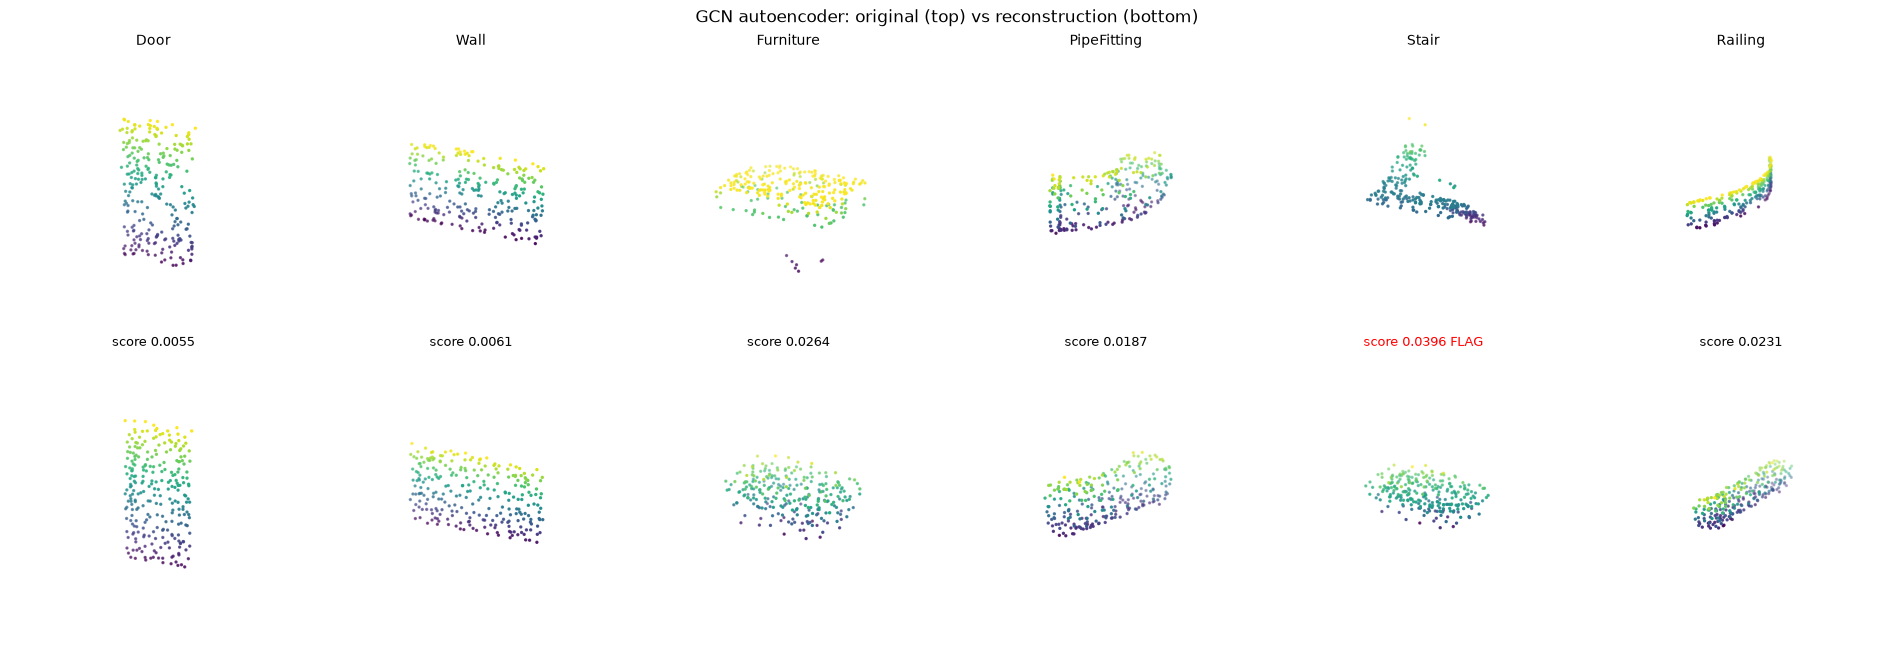

In [34]:
import matplotlib.pyplot as plt

SHOW_RECON = ["IfcDoor", "IfcWall", "IfcFurniture", "IfcPipeFitting", "IfcStair", "IfcRailing"]
picked = []
for cls in SHOW_RECON:
    idx = np.where(test_labels == cls)[0]
    if len(idx):
        picked.append((cls, int(idx[0])))          # first test object of that class

model.eval()
fig = plt.figure(figsize=(3.2 * len(picked), 6.6))
for j, (cls, i) in enumerate(picked):
    batch = next(iter(DataLoader([test_graphs[i]], batch_size=1))).to(DEVICE)
    with torch.no_grad():
        pred, _ = model(batch)
    original = batch.pos[:LOSS_POINTS].cpu().numpy()    # same 256 points the loss was trained on
    rebuilt = pred[0, :LOSS_POINTS].cpu().numpy()
    flagged = test_scores[i] > threshold
    for row, (pts, name) in enumerate([(original, "original"), (rebuilt, "reconstruction")]):
        ax = fig.add_subplot(2, len(picked), row * len(picked) + j + 1, projection="3d")
        ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=2, c=pts[:, 2], cmap="viridis")
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
        ax.set_box_aspect((1, 1, 1)); ax.view_init(elev=20, azim=-60); ax.set_axis_off()
        if row == 0:
            ax.set_title(cls.replace("Ifc", ""), fontsize=10)
        else:
            ax.set_title(f"score {test_scores[i]:.4f}" + (" FLAG" if flagged else ""),
                         fontsize=9, color="red" if flagged else "black")
fig.suptitle("GCN autoencoder: original (top) vs reconstruction (bottom)", fontsize=12)
fig.tight_layout()
fig.savefig("../figures/ifc_06_reconstructions.png", dpi=150)
plt.show()


## 10. Comparison, baseline, and export check

We compare the selected GCN with a dropout-regularized GCN and a simple raw-geometry nearest-neighbour baseline. All models use the same data split and seed.

In [35]:
import matplotlib.pyplot as plt

DROPOUT_EPOCHS = 30   # about 10 min per epoch on a laptop CPU; 5 is enough for a quick comparison

def train_setup(dropout, epochs=DROPOUT_EPOCHS):
    candidate = GraphAutoencoder(latent_dim=32, hidden_dim=64, dropout=dropout).to(DEVICE)
    opt = torch.optim.Adam(candidate.parameters(), lr=1e-3, weight_decay=1e-5)
    rows, best_val = [], float('inf')
    path = f'../../data/gcn_dropout_{dropout}.pt'
    for ep in range(1, epochs + 1):
        candidate.train(); train_total = 0.0
        for data in loader:
            data = data.to(DEVICE); opt.zero_grad()
            pred, _ = candidate(data)
            target = data.pos.reshape(-1, 1024, 3)[:, :LOSS_POINTS]
            loss = chamfer_distance(pred[:, :LOSS_POINTS], target)
            loss.backward(); opt.step(); train_total += loss.item() * data.num_graphs
        candidate.eval(); val_total = 0.0
        with torch.no_grad():
            for data in val_loader:
                data = data.to(DEVICE); pred, _ = candidate(data)
                target = data.pos.reshape(-1, 1024, 3)[:, :LOSS_POINTS]
                val_total += chamfer_distance(pred[:, :LOSS_POINTS], target).item() * data.num_graphs
        val_loss = val_total / len(val_loader.dataset)
        rows.append({'epoch': ep, 'train_chamfer': train_total / len(loader.dataset), 'val_chamfer': val_loss})
        if val_loss < best_val:
            best_val = val_loss; torch.save(candidate.state_dict(), path)
        print(f'dropout={dropout} epoch={ep:02d} train={rows[-1]["train_chamfer"]:.6f} val={val_loss:.6f}')
    candidate.load_state_dict(torch.load(path, weights_only=True))   # keep the best epoch
    return candidate.eval(), pd.DataFrame(rows)

dropout_model, dropout_history = train_setup(0.20)

dropout=0.2 epoch=01 train=0.052272 val=0.028401


dropout=0.2 epoch=02 train=0.026264 val=0.025249


dropout=0.2 epoch=03 train=0.024517 val=0.025435


dropout=0.2 epoch=04 train=0.023910 val=0.025429


dropout=0.2 epoch=05 train=0.023198 val=0.025204


dropout=0.2 epoch=06 train=0.023053 val=0.023122


... (20 outputs left out)

dropout=0.2 epoch=27 train=0.015973 val=0.016560


dropout=0.2 epoch=28 train=0.015919 val=0.016143


dropout=0.2 epoch=29 train=0.015847 val=0.015721


dropout=0.2 epoch=30 train=0.015703 val=0.015842


### 10.1 Training curves and raw-geometry baseline

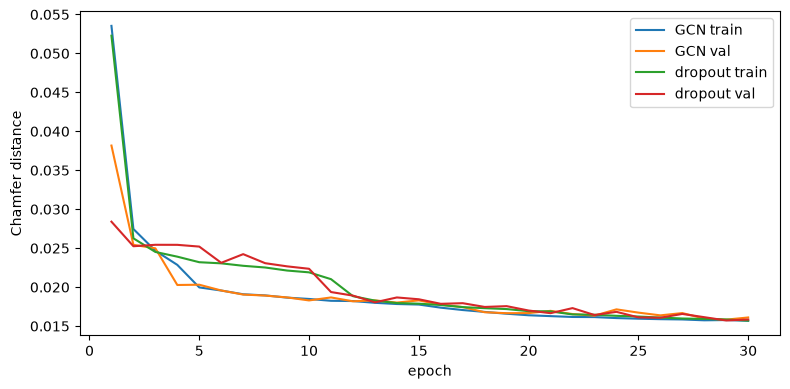

raw geometry baseline P@5: 0.3795


In [36]:
plt.figure(figsize=(8, 4))
if 'history' in globals() and len(history):
    base_history = pd.DataFrame(history)
    plt.plot(base_history['epoch'], base_history['train_chamfer'], label='GCN train')
    plt.plot(base_history['epoch'], base_history['val_chamfer'], label='GCN val')
if 'dropout_history' in globals():
    plt.plot(dropout_history['epoch'], dropout_history['train_chamfer'], label='dropout train')
    plt.plot(dropout_history['epoch'], dropout_history['val_chamfer'], label='dropout val')
plt.xlabel('epoch'); plt.ylabel('Chamfer distance'); plt.legend(); plt.tight_layout()
plt.savefig('../figures/p2_training_curves.png', dpi=160); plt.show()

raw = test_graphs.points[test_graphs.indices].reshape(len(test_graphs), -1).numpy()
raw_p5 = precision_at_5(raw, test_labels, metric='euclidean')
print('raw geometry baseline P@5:', round(raw_p5, 4))

### 10.2 Final comparison table and ONNX smoke test

The export test is intentionally a smoke test for deployment: it checks whether the model’s tensor interface can be exported before deployment work begins.

In [37]:
rows = [{'model': 'GCN', 'P@5': p_at_5, 'ROC_AUC': gcn['roc_auc'],
         'precision': gcn['precision'], 'recall': gcn['recall'], 'threshold': gcn['threshold'], 'baseline': False}]
if 'dropout_model' in globals():
    drop = anomaly_metrics(dropout_model)
    rows.append({'model': 'GCN + dropout 0.2', 'P@5': precision_at_5(embeddings(test_graphs, dropout_model), test_labels),
                 'ROC_AUC': drop['roc_auc'], 'precision': drop['precision'], 'recall': drop['recall'],
                 'threshold': drop['threshold'], 'baseline': False})
rows.append({'model': 'Raw geometry', 'P@5': raw_p5, 'ROC_AUC': np.nan, 'precision': np.nan,
             'recall': np.nan, 'threshold': np.nan, 'baseline': True})
results = pd.DataFrame(rows).round(4)
results.to_csv('../comparison_graph.csv', index=False)
display(results)

# Export the best GCN checkpoint for the model server (02_model_server/model/model.onnx + config.json).
# Restart app.py afterwards so it loads the new files.
import export_gcn_server
importlib.reload(export_gcn_server)
export_gcn_server.main()

,model,P@5,ROC_AUC,precision,recall,threshold,baseline
0,GCN,0.3856,0.5342,0.2313,0.2168,0.0393,False
1,GCN + dropout 0.2,0.3905,0.5324,0.2230,0.2168,0.0383,False
2,Raw geometry,0.3795,NaN,NaN,NaN,NaN,True


threshold (95th pct of 784 normal val graphs): 0.039336


/opt/anaconda3/envs/Hackathon/lib/python3.12/site-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset9.py:5330: UserWarning: Exporting aten::index operator with indices of type Byte. Only 1-D indices are supported. In any other case, this will produce an incorrect ONNX graph.
  indices = [try_mask_to_index(idx) for idx in indices]


max diff recon: 4.76837158203125e-07 latent: 3.5762786865234375e-07
wrote /Users/emmanuelmarquez/Documents/IAAC/Hackaton/group2_hackathon/02_model_server/model/model.onnx and /Users/emmanuelmarquez/Documents/IAAC/Hackaton/group2_hackathon/02_model_server/model/config.json


### 11 Conclusion
- Convolutions on images beat dense layers on images, and images beat raw 3D geometry for this task in our setup.
- The 3D approaches (point cloud and graph) are closer to real IFC data but, as trained here, the reconstruction error measures *how complex* an element is, not *how unusual* it is. Their latent space is more useful than their reconstruction error.
- None of the models is reliable enough to work alone: even conv_64 has precision 0.47, so about half of its alarms are false. It is a **screening tool** that tells a BIM coordinator where to look, not an automatic checker.
- **Limitations:** only two anomaly classes, one seed, small inputs (64 px or 1,024 points), short CPU training, clean renders only.
- **Next steps for 3D:** a stronger encoder (DGCNN / pretrained point features), a better decoder, keeping real dimensions instead of scaling to the unit sphere, and longer GPU training.

### 12 Test that a graph layer exports to ONNX

In [38]:
import inspect
from pathlib import Path

import numpy as np
import onnxruntime as ort
import torch
from torch_geometric.nn import GCNConv, global_mean_pool

torch.manual_seed(42)
N_POINTS, K = 1024, 16


class Tiny(torch.nn.Module):
    """One graph layer -> average over all points -> small latent vector."""
    def __init__(self):
        super().__init__()
        self.conv = GCNConv(3, 64)
        self.lin = torch.nn.Linear(64, 32)

    def forward(self, x, edge_index):
        batch = torch.zeros_like(x[:, 0], dtype=torch.long)   # all points belong to graph 0
        h = self.conv(x, edge_index).relu()
        return self.lin(global_mean_pool(h, batch))


# random graph with our real sizes: x [1024, 3], edge_index [2, 16384]
x = torch.randn(N_POINTS, 3)
src = torch.randint(0, N_POINTS, (N_POINTS * K,))
dst = torch.arange(N_POINTS).repeat_interleave(K)
edge_index = torch.stack([src, dst])

model = Tiny().eval()
out_path = Path("tiny_layer_test.onnx")

kw = dict(input_names=["x", "edge_index"], output_names=["latent"], opset_version=17)
if "dynamo" in inspect.signature(torch.onnx.export).parameters:
    kw["dynamo"] = False          # use the classic exporter (more stable for PyG)

with torch.no_grad():
    torch.onnx.export(model, (x, edge_index), str(out_path), **kw)
    z_pt = model(x, edge_index).numpy()

sess = ort.InferenceSession(str(out_path), providers=["CPUExecutionProvider"])
z_ox = sess.run(None, {"x": x.numpy(), "edge_index": edge_index.numpy()})[0]

diff = float(np.abs(z_pt - z_ox).max())
print("max difference PyTorch vs ONNX:", diff)
print("PASSED: graph layers export fine" if diff < 1e-4 else "FAILED: outputs differ")
out_path.unlink()   # delete the test file

max difference PyTorch vs ONNX: 1.4901161193847656e-08
PASSED: graph layers export fine


/var/folders/qc/7v0ppfhx32g4dj_7pwr250nw0000gn/T/ipykernel_1375/1379024684.py:40: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, (x, edge_index), str(out_path), **kw)


### 12.1 Export the trained model to ONNX

In [39]:
import inspect
import sys
from pathlib import Path

import numpy as np
import onnxruntime as ort
import torch
from torch_geometric.data import Batch

# Repo root: __file__ does not exist in a notebook, so walk up from the current folder instead
try:
    start = Path(__file__).resolve().parent
except NameError:
    start = Path.cwd().resolve()
REPO = next(p for p in [start, *start.parents] if (p / "01_autoencoder" / "src").is_dir())
sys.path.insert(0, str(REPO / "01_autoencoder" / "src"))
from graph_autoencoder import GraphAutoencoder, LazyGraphDataset   # P2's model + lazy dataset

DATA = REPO / "data"
OUT = REPO / "01_autoencoder" / "model"
OUT.mkdir(parents=True, exist_ok=True)

# 1) Load the trained model (same settings as in the notebook)
ck = torch.load(DATA / "gcn_autoencoder.pt", map_location="cpu", weights_only=False)
model = GraphAutoencoder(latent_dim=ck.get("latent_dim", 32), hidden_dim=64)
model.load_state_dict(ck["model"])
model.eval()


# 2) Wrapper: ONNX only takes plain tensors, so call encode/decode directly
class OnnxWrapper(torch.nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net

    def forward(self, x, edge_index):
        batch = torch.zeros(x.shape[0], dtype=torch.long)    # one graph
        z = self.net.encode(x, edge_index, batch)
        return self.net.decode(z), z


# 3) A real graph as example input (only builds the graphs we index)
val_graphs = LazyGraphDataset(DATA / "ifc_graphs" / "val.pt")
g0 = val_graphs[0]
x0 = g0.x.float()
ei0 = g0.edge_index.long()

kw = dict(input_names=["x", "edge_index"],
          output_names=["reconstruction", "latent"],
          dynamic_axes={"edge_index": {1: "n_edges"}},
          opset_version=17)
if "dynamo" in inspect.signature(torch.onnx.export).parameters:
    kw["dynamo"] = False

onnx_path = OUT / "model.onnx"
with torch.no_grad():
    torch.onnx.export(OnnxWrapper(model).eval(), (x0, ei0), str(onnx_path), **kw)
print("exported", onnx_path, round(onnx_path.stat().st_size / 1e6, 2), "MB")

# 4) Check: same graphs through PyTorch (the normal way) and through ONNX
sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
worst = 0.0
for g in val_graphs[:5]:
    with torch.no_grad():
        r_pt, z_pt = model(Batch.from_data_list([g]))
    r_ox, z_ox = sess.run(None, {"x": g.x.numpy().astype(np.float32),
                                 "edge_index": g.edge_index.numpy().astype(np.int64)})
    d_rec = float(np.abs(r_ox.reshape(-1) - r_pt.numpy().reshape(-1)).max())
    d_lat = float(np.abs(z_ox.reshape(-1) - z_pt.numpy().reshape(-1)).max())
    worst = max(worst, d_rec, d_lat)
    print(f"{g.object_id[:8]}  max diff reconstruction {d_rec:.2e}  latent {d_lat:.2e}")

assert worst < 1e-4, "ONNX and PyTorch disagree -> do not use this file"
print("ONNX check OK: matches PyTorch")


exported /Users/emmanuelmarquez/Documents/IAAC/Hackaton/group2_hackathon/01_autoencoder/model/model.onnx 7.03 MB
00780c6f  max diff reconstruction 4.77e-07  latent 3.58e-07


/var/folders/qc/7v0ppfhx32g4dj_7pwr250nw0000gn/T/ipykernel_1375/373351982.py:57: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(OnnxWrapper(model).eval(), (x0, ei0), str(onnx_path), **kw)
/opt/anaconda3/envs/Hackathon/lib/python3.12/site-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset9.py:5330: UserWarning: Exporting aten::index operator with indices of type Byte. Only 1-D indices are supported. In any other case, this will produce an incorrect ONNX graph.
  indices = [try_mask_to_index(idx) for idx in indices]


0aa9cb02  max diff reconstruction 3.58e-07  latent 3.58e-07
0ee82272  max diff reconstruction 5.36e-07  latent 5.36e-07


0f2ee23b  max diff reconstruction 5.51e-07  latent 3.28e-07
1a6be9fd  max diff reconstruction 2.98e-07  latent 3.58e-07
ONNX check OK: matches PyTorch


### 12.2 Threshold

In [40]:
import json
import shutil
import sys
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import onnxruntime as ort
import pandas as pd

# Repo root: __file__ does not exist in a notebook, so walk up from the current folder instead
try:
    start = Path(__file__).resolve().parent
except NameError:
    start = Path.cwd().resolve()
REPO = next(p for p in [start, *start.parents] if (p / "01_autoencoder" / "src").is_dir())
sys.path.insert(0, str(REPO / "01_autoencoder" / "src"))
import ifc_graph
from graph_autoencoder import LazyGraphDataset

DATA = REPO / "data"
OUT = REPO / "01_autoencoder" / "model"
ANOM = ["IfcStair", "IfcRailing"]       # same anomaly classes as the notebook
SCORE_POINTS = 256                      # notebook compares the first 256 points (LOSS_POINTS)

sess = ort.InferenceSession(str(OUT / "model.onnx"), providers=["CPUExecutionProvider"])
split = pd.read_csv(REPO / "01_autoencoder" / "splits" / "ifc_split.csv")


def chamfer(a, b):
    """Chamfer distance: for each point, distance to the closest point of the other cloud (both ways)."""
    d = ((a[:, None, :] - b[None, :, :]) ** 2).sum(-1)
    return float(d.min(1).mean() + d.min(0).mean())


def run_graph(g):
    """graph -> ONNX -> (score, latent)."""
    recon, z = sess.run(None, {"x": g.x.numpy().astype(np.float32),
                               "edge_index": g.edge_index.numpy().astype(np.int64)})
    s = chamfer(recon.reshape(-1, 3)[:SCORE_POINTS], g.pos.numpy()[:SCORE_POINTS])
    return s, z[0]


def pkg_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


# 1) Threshold = 95th percentile of the score on NORMAL validation objects
normal_val_ids = split.loc[(split["split"] == "val") & ~split["ifc_class"].isin(ANOM), "object_id"]
val = LazyGraphDataset(DATA / "ifc_graphs" / "val.pt", normal_val_ids)   # builds one graph at a time
normal_scores = np.array([run_graph(val[i])[0] for i in range(len(val))])
thr = float(np.quantile(normal_scores, 0.95))
print(f"threshold (95th pct of {len(normal_scores)} normal val objects): {thr:.6f}")

# 2) Three example IFC files from the TEST set: 2 normal + 1 anomaly
ex_dir = OUT / "examples"
ex_dir.mkdir(parents=True, exist_ok=True)
for f in ex_dir.glob("*.ifc"):
    f.unlink()
test = split[split["split"] == "test"].sort_values("object_id")
for cls, kind in [("IfcDoor", "normal"), ("IfcWall", "normal"), ("IfcStair", "anomaly")]:
    row = test[test["ifc_class"] == cls].iloc[0]
    shutil.copy(DATA / row["path"], ex_dir / f"{kind}_{cls}.ifc")

# 3) config.json: everything the server needs
cfg = {
    "model_file": "model.onnx",
    "model_name": "GCN graph autoencoder (data/gcn_autoencoder.pt)",
    "inputs": {"x": "[1024, 3] float32, normalised xyz of the points",
               "edge_index": "[2, 16384] int64, kNN edges (16 neighbours)"},
    "outputs": {"reconstruction": "[1, 1024, 3]", "latent": f"[1, {sess.get_outputs()[1].shape[-1]}]"},
    "preprocessing": {
        "function": "ifc_graph.ifc_to_graph(path)",
        "n_points": ifc_graph.N_POINTS,
        "k_neighbours": ifc_graph.K_NEIGHBOURS,
        "seed": ifc_graph.SEED,
        "notes": "IFC -> mesh in world coordinates -> sample points -> centre + scale -> kNN graph",
    },
    "score": "Chamfer distance between reconstruction and input points (first 256 points)",
    "score_points": SCORE_POINTS,
    "threshold": thr,
    "threshold_rule": "95th percentile of the score on normal validation objects",
    "decision": "score > threshold -> 'unusual object, check it'",
    "anomaly_classes_used_in_eval": ANOM,
    "built_with": {"python": sys.version.split()[0], "torch": pkg_version("torch"),
                   "torch_geometric": pkg_version("torch_geometric"),
                   "ifcopenshell": ifc_graph.ifcopenshell.version, "onnxruntime": ort.__version__,
                   "gradio": pkg_version("gradio"), "numpy": np.__version__},
}
(OUT / "config.json").write_text(json.dumps(cfg, indent=2))
print("saved", OUT / "config.json")

# 4) Full check from the raw IFC file (same path as the server)
for f in sorted(ex_dir.glob("*.ifc")):
    s, z = run_graph(ifc_graph.ifc_to_graph(f))
    print(f"{f.name:25s} score {s:.6f}  {'UNUSUAL' if s > thr else 'ok'}   latent size {len(z)}")


threshold (95th pct of 784 normal val objects): 0.039336
saved /Users/emmanuelmarquez/Documents/IAAC/Hackaton/group2_hackathon/01_autoencoder/model/config.json
anomaly_IfcStair.ifc      score 0.039607  UNUSUAL   latent size 32


normal_IfcDoor.ifc        score 0.005460  ok   latent size 32
normal_IfcWall.ifc        score 0.006099  ok   latent size 32
